# 7. Predictive Analysis (Classification)
Compare four classifiers with GridSearchCV and evaluate the best on the test set.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix

data = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv')
X = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_3.csv')
Y = data['Class'].to_numpy()
X = preprocessing.StandardScaler().fit(X).transform(X)
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)
print(X_train.shape, X_test.shape)

(72, 83) (18, 83)


In [2]:
def plot_cm(y, y_pred, title):
    cm = confusion_matrix(y, y_pred)
    ax = plt.subplot()
    sns.heatmap(cm, annot=True, ax=ax)
    ax.set_xlabel('Predicted labels'); ax.set_ylabel('True labels')
    ax.set_title(title)
    ax.xaxis.set_ticklabels(['did not land', 'land']); ax.yaxis.set_ticklabels(['did not land', 'land'])
    plt.show()

models = {
    'Logistic Regression': (LogisticRegression(),
        {'C': [0.01, 0.1, 1], 'penalty': ['l2'], 'solver': ['lbfgs']}),
    'Support Vector Machine': (SVC(),
        {'kernel': ['linear', 'rbf', 'poly', 'sigmoid'], 'C': np.logspace(-3, 3, 5), 'gamma': np.logspace(-3, 3, 5)}),
    'Decision Tree': (DecisionTreeClassifier(),
        {'criterion': ['gini', 'entropy'], 'splitter': ['best', 'random'], 'max_depth': [2 * n for n in range(1, 10)],
         'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2, 4], 'min_samples_split': [2, 5, 10]}),
    'K-Nearest Neighbours': (KNeighborsClassifier(),
        {'n_neighbors': list(range(1, 11)), 'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'], 'p': [1, 2]}),
}
results, fitted = {}, {}
for name, (est, grid) in models.items():
    gs = GridSearchCV(est, grid, cv=10)
    gs.fit(X_train, Y_train)
    results[name] = gs.score(X_test, Y_test)
    fitted[name] = gs
    print(name, '| best CV accuracy: %.4f | test accuracy: %.4f' % (gs.best_score_, results[name]))
    print('   best params:', gs.best_params_)

Logistic Regression | best CV accuracy: 0.8464 | test accuracy: 0.8333
   best params: {'C': 0.01, 'penalty': 'l2', 'solver': 'lbfgs'}
Support Vector Machine | best CV accuracy: 0.8482 | test accuracy: 0.8333
   best params: {'C': np.float64(1.0), 'gamma': np.float64(0.03162277660168379), 'kernel': 'sigmoid'}
Decision Tree | best CV accuracy: 0.8875 | test accuracy: 0.6111
   best params: {'criterion': 'gini', 'max_depth': 16, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'splitter': 'random'}
K-Nearest Neighbours | best CV accuracy: 0.8482 | test accuracy: 0.8333
   best params: {'algorithm': 'auto', 'n_neighbors': 10, 'p': 1}


In [3]:
summary = pd.DataFrame({'Model': list(results.keys()), 'Test accuracy': list(results.values())})
summary = summary.sort_values('Test accuracy', ascending=False).reset_index(drop=True)
summary

,Model,Test accuracy
0,Logistic Regression,0.833333
1,Support Vector Machine,0.833333
2,K-Nearest Neighbours,0.833333
3,Decision Tree,0.611111


Best model: Logistic Regression | accuracy: 0.8333


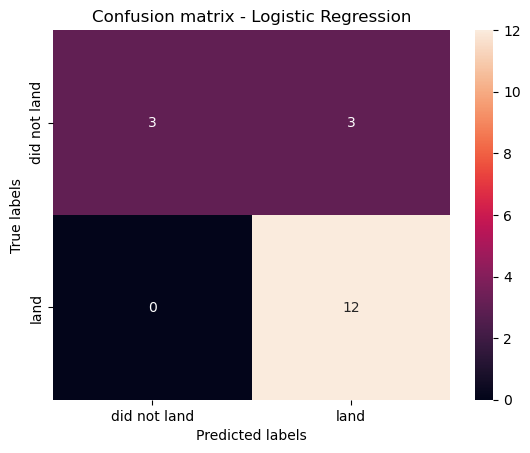

In [4]:
best_name = summary.loc[0, 'Model']
print('Best model:', best_name, '| accuracy: %.4f' % summary.loc[0, 'Test accuracy'])
plot_cm(Y_test, fitted[best_name].predict(X_test), 'Confusion matrix - ' + best_name)

Write your conclusion here: which model is best, what the confusion matrix shows (e.g. false positives), and one idea to improve it.